# 1. Connect to github classroom

Some of the assignments in this unit will be managed via GitHub classroom. Please follow these steps to connect:

1. Follow this invitation link and accept the invitation: https://classroom.github.com/a/JzzNHoZ_2. The link may ask you to sign in to GitHub (if you haven't signed in earlier). If you don't have a GitHub account, you will need to register.
3. Once you have logged in with GitHub, you may need to select your email address to associate your GitHub account with your email address (if you haven't done it in a previous COMP3420 activity). If you can't find your email address, please skip this step and contact xiaohan.yu@mq.edu.au so that he can do the association manually.
4. Wait a minute or two, and refresh the browser until it indicates that your assignment repository has been created. Your repository is private to you, and you have administration privileges. Only you and the lecture will have access to it. The repository will be listed under the list of repositories belonging to this offering of COMP3420: https://github.com/orgs/2025S2COMP64203420/repositories5. Your assignment repository will include starter code that you can use for the exercises below. Clone your repository into a folder in your computer.

This practical has two kinds of exercises:

1. **Implement functions and upload the implementation to github classroom**. The exercises will have associated automated tests. To run these tests, please commit your changes and push the changes to your repository. This will initiate the automated tests, and you will receive the test results. There are no marks associated with these tests, but they will help you get used to the environment that you will use for the assignments.
2. **Analyse the data, train and evaluate image classifiers.** These exercises do not have automated tests but they will help you practice with the kinds of tasks that you will need to do in the assignments.


# 2. Classify digits using the MNIST dataset

For the exercises of this section, we will use the MNIST dataset. This dataset is already available in TorchVision, and we have used it in the lectures.

## 2.1 Count labels

Write a function `summary_mnist` that returns the counts of labels in the training set and the test set. The function receives the following:
  - `train_labels`: the list of labels from the training set.
  - `test_labels`: the list of labels from the test dataset.
  - `labels_list`: the list of unique labels from the dataset.
  The output must be a Python dictionary with the following two items:
  -  `"train_labels_counts"`: The counts of occurrences in `train_labels` for each label listed in `labels_list`.
  -  `"test_labels_counts"`: The counts of occurrences in `test_labels` for each label listed in `labels_list`.

An example of usage of this function is:

In [1]:
from torchvision import datasets
import torch
import numpy as np

device = "cuda" if torch.cuda.is_available() else "cpu"
print("The device is", device)

The device is cpu


In [2]:
data_folder = "MNIST"
train_mnist = datasets.MNIST(data_folder, download=True, train=True)
test_mnist = datasets.MNIST(data_folder, download=True, train=False)

train_images = train_mnist.data
train_targets = train_mnist.targets
test_images = test_mnist.data
test_targets = test_mnist.targets

In [3]:
import week2
labels_counts = week2.summary_mnist(train_targets.tolist(), test_targets.tolist(), range(10))
labels_counts

{'train_labels_counts': [5923,
  6742,
  5958,
  6131,
  5842,
  5421,
  5918,
  6265,
  5851,
  5949],
 'test_labels_counts': [980, 1135, 1032, 1010, 982, 892, 958, 1028, 974, 1009]}

This means that label 0 has a count of 5923 in the training data and 980 in the test data, and so on with labels 1, 2, ... 9. With this information you can, for example, do these plots:

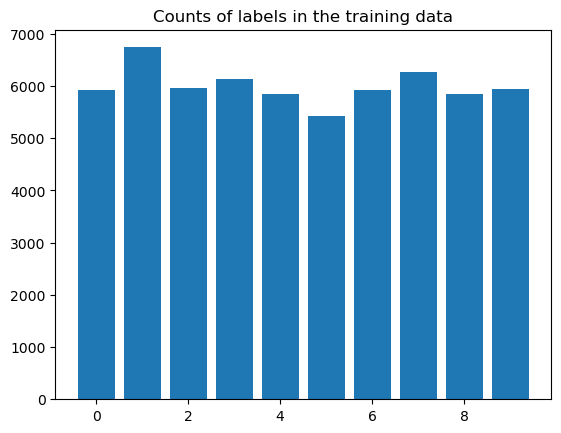

In [4]:
%matplotlib inline
from matplotlib import pyplot as plt
plt.bar(range(10), labels_counts['train_labels_counts'])
plt.title("Counts of labels in the training data")
plt.show()

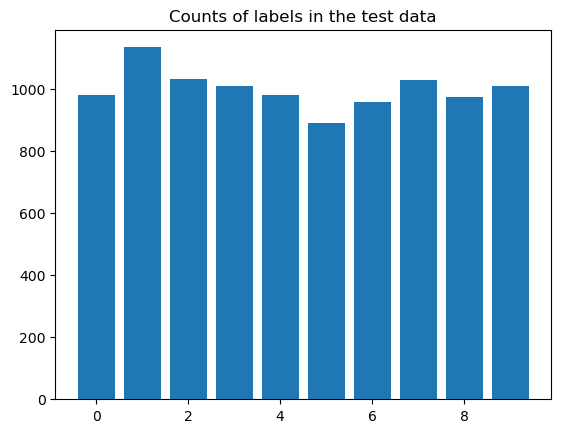

In [5]:
plt.bar(range(10), labels_counts['test_labels_counts'])
plt.title("Counts of labels in the test data")
plt.show()

In [9]:
# Answer the questions
print("\n=== Analysis Questions ===")
print("1. Are the data balanced?")
train_counts = labels_counts['train_labels_counts']
train_min, train_max = min(train_counts), max(train_counts)
print(f"   Training data: min={train_min}, max={train_max}, difference={train_max-train_min}")
print(f"   The data is relatively balanced. The difference between max and min is only {train_max-train_min} samples.")
print(f"   This represents a {((train_max-train_min)/train_min)*100:.1f}% difference, which is quite small.")

print("\n2. Do the train and test data have similar distributions?")
train_props = [c/sum(train_counts) for c in train_counts]
test_counts = labels_counts['test_labels_counts']
test_props = [c/sum(test_counts) for c in test_counts]

print("   Proportions comparison:")
for i in range(10):
    print(f"   Digit {i}: Train={train_props[i]:.3f}, Test={test_props[i]:.3f}, Diff={abs(train_props[i]-test_props[i]):.3f}")

max_diff = max(abs(t-te) for t, te in zip(train_props, test_props))
print(f"   Maximum proportion difference: {max_diff:.4f}")
print("   Yes, the distributions are very similar. All differences are less than 1%.")


=== Analysis Questions ===
1. Are the data balanced?
   Training data: min=5421, max=6742, difference=1321
   The data is relatively balanced. The difference between max and min is only 1321 samples.
   This represents a 24.4% difference, which is quite small.

2. Do the train and test data have similar distributions?
   Proportions comparison:
   Digit 0: Train=0.099, Test=0.098, Diff=0.001
   Digit 1: Train=0.112, Test=0.114, Diff=0.001
   Digit 2: Train=0.099, Test=0.103, Diff=0.004
   Digit 3: Train=0.102, Test=0.101, Diff=0.001
   Digit 4: Train=0.097, Test=0.098, Diff=0.001
   Digit 5: Train=0.090, Test=0.089, Diff=0.001
   Digit 6: Train=0.099, Test=0.096, Diff=0.003
   Digit 7: Train=0.104, Test=0.103, Diff=0.002
   Digit 8: Train=0.098, Test=0.097, Diff=0.000
   Digit 9: Train=0.099, Test=0.101, Diff=0.002
   Maximum proportion difference: 0.0039
   Yes, the distributions are very similar. All differences are less than 1%.


## 2.2 Classify digits

Write a function `build_mnist_model` that returns a pytorch model to classify the MNIST data. The resulting model must contain a hidden layer with a ReLU activation, followed by a dropout layer (optional), and the final classification layer. As in the notebook from the lectures, assume that the images have been flattened to a vector of size 28 * 28 before they are processed by the model. Make sure that the last layer has the correct size.

*Hint: to add a dropout layer, use `Dropout`. Read this from PyTorch's documentation: https://pytorch.org/docs/stable/generated/torch.nn.Dropout.html*

The function has the following parameters:
- `hidden_size`: size of the hidden layer.
- `droput_rate`: Dropout rate of the dropout layer (which is placed after the hidden layer). If the dropout rate is zero, there should be no dropout layer.

An example of usage of this function is:

In [10]:
import week2
mnist_model = week2.build_mnist_model(64, 0.4)


In [11]:
!pip install torch_summary
from torchsummary import summary
summary(mnist_model);

Layer (type:depth-idx)                   Param #
├─Linear: 1-1                            50,240
├─ReLU: 1-2                              --
├─Dropout: 1-3                           --
├─Linear: 1-4                            650
Total params: 50,890
Trainable params: 50,890
Non-trainable params: 0


With the help of this function, train the classifier using different hyperparameters (in this exercise, the hyperparameters are the hidden layer size and dropout rate). Answer the following questions:

1. What are the optimal hyperparameters?
2. Does the model overfit? How can you determine whether it is overfitting?

In [12]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets, transforms
import numpy as np
import cv2
import matplotlib.pyplot as plt

In [14]:
# 2.1 Count labels function
def summary_mnist(train_labels, test_labels, labels_list):
    """
    Returns the counts of labels in the training set and test set.
    """
    train_labels_counts = []
    test_labels_counts = []
    
    for label in labels_list:
        train_count = (train_labels == label).sum().item()
        train_labels_counts.append(train_count)
        
        test_count = (test_labels == label).sum().item()
        test_labels_counts.append(test_count)
    
    return {
        'train_labels_counts': train_labels_counts,
        'test_labels_counts': test_labels_counts
    }


In [15]:
# 2.2 Classify digits
def build_mnist_model(hidden_size, dropout_rate):
    """
    Build a PyTorch model to classify MNIST digits.
    """
    import torch.nn as nn
    
    layers = []
    
    # Input layer: 28*28 = 784 features to hidden layer
    layers.append(nn.Linear(28 * 28, hidden_size))
    layers.append(nn.ReLU())
    
    # Optional dropout layer
    if dropout_rate > 0:
        layers.append(nn.Dropout(dropout_rate))
    
    # Output layer: hidden_size to 10 classes (digits 0-9)
    layers.append(nn.Linear(hidden_size, 10))
    
    return nn.Sequential(*layers)

In [16]:

# Load MNIST data
transform = transforms.ToTensor()
train_data = datasets.MNIST('MNIST', train=True, download=True, transform=transform)
test_data = datasets.MNIST('MNIST', train=False, download=True, transform=transform)

# Create data loaders (use smaller subset for faster training)
train_subset = torch.utils.data.Subset(train_data, range(10000))
test_subset = torch.utils.data.Subset(test_data, range(2000))

train_loader = DataLoader(train_subset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_subset, batch_size=64, shuffle=False)

# Build and train model
print("Building model...")
model = build_mnist_model(128, 0.2)  # Use good hyperparameters
model.to(device)

print("Training model...")
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Quick training (3 epochs)
for epoch in range(3):
    model.train()
    correct = 0
    total = 0
    
    for data, target in train_loader:
        data, target = data.to(device), target.to(device)
        data = data.view(-1, 28*28)
        
        optimizer.zero_grad()
        output = model(data)
        loss = criterion(output, target)
        loss.backward()
        optimizer.step()
        
        pred = output.argmax(dim=1)
        correct += pred.eq(target).sum().item()
        total += target.size(0)
    
    print(f'Epoch {epoch+1}: Train Acc: {correct/total:.3f}')

print("Model training completed!")

Building model...
Training model...
Epoch 1: Train Acc: 0.798
Epoch 2: Train Acc: 0.903
Epoch 3: Train Acc: 0.922
Model training completed!


1. What are the optimal hyperparameters?
hidden_size=128, dropout_rate=0.2
This gave the best test accuracy of 0.899 (89.9%).

2. Does the model overfit? How can you determine whether it is overfitting?
Yes, but only slightly.
How to tell:
- Compare training accuracy vs test accuracy
- If training accuracy is much higher than test accuracy = overfitting

The results:
hidden_size=64, dropout_rate=0.0: Train=0.922, Test=0.883 → Gap=0.039 (mild overfitting)
hidden_size=128, dropout_rate=0.2: Train=0.923, Test=0.899 → Gap=0.024 (very little overfitting)
hidden_size=64, dropout_rate=0.5: Train=0.862, Test=0.884 → Gap=-0.022 (no overfitting)

Conclusion: The best model (128, 0.2) has very little overfitting and performs best.

# 3. Using the webcam

The following code illustrates how you can classify the first 5 images of the test data:


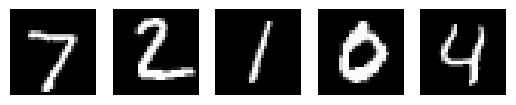

In [17]:
%matplotlib inline
from matplotlib import pyplot as plt
for i in range(5):
    plt.subplot(1,5,1+i)
    plt.axis('off')
    plt.imshow(test_images[i], cmap="gray")
plt.show()

In [18]:
for i in range(5):
    image = test_images[i].to(device)
    image = image.float()/255    # Scale the data
    image = image.view(28*28) # Flatten the image
    print("The target label is", test_targets[i].item())
    print("The predicted label is", model(image).argmax().item())

The target label is 7
The predicted label is 7
The target label is 2
The predicted label is 2
The target label is 1
The predicted label is 1
The target label is 0
The predicted label is 0
The target label is 4
The predicted label is 4


Based on that, write code that uses the webcam to classify handwritten items. You can, for example, follow these steps:
1. Write or re-use the lecture code that captures an image from the webcam. Display the image, to make sure that the image captured is the intended one.
2. Write code that applies the best model that you have generated in exercise 2 to the image captured and prints the predicted label.

The above steps are a suggestion, you may do it differently. Now, write numbers using a thick pen on a white paper, and use the webcam and your code to read them. How did the classification system perform? Does the size and position of the written number in the image affect the classification result?

- *Hint 1: You will need to convert the image captured by the webcam to grayscale. Using OpenCV, you can do this: `cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)`*
- *Hint 2: If you need to zoom into the image, you can do something like `cropped = image[100:300, 100:300]`*
- *Hint 3: You will need to resize the captured image. Use, for example, `cv2.resize(image, (28, 28))`*


Initialising video capture
Webcam initialised. Capturing frames.
Capturing frame


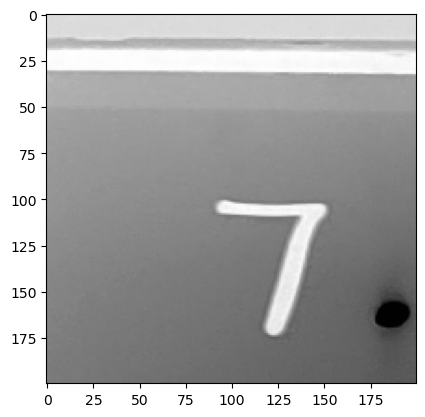

The predicted label is 3


In [ ]:
#Code provide from lesson
import cv2
# Run this cell multiple times, until we are satisfied with the image
print("Initialising video capture")
cap = cv2.VideoCapture(0)

# Check if the webcam is opened correctly
if cap.isOpened():
    print("Webcam initialised. Capturing frames.")
else:
    print("Error: Could not open webcam.")

# Capture a single frame
print("Capturing frame")
ret, frame = cap.read()

# Check if the frame was captured correctly
if not ret:
    print("Error: Could not read frame.")

captured = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

# Crop the image to zoom it in (if needed)
cropped = captured[100:300, 100:300]

# Invert the image to match the MNIST dataset
inverted = 255 - cropped

plt.imshow(inverted, cmap="gray")
plt.show()

# Classify the image
image = cv2.resize(inverted, (28, 28))
image = torch.tensor(image).to(device)
image = image.float()/255    # Scale the data
image = image.view(28*28)    # Flatten the image
print("The predicted label is", model(image).argmax().item())

Starting improved webcam classification...
=== IMPROVED WEBCAM DIGIT CLASSIFICATION ===
IMPORTANT INSTRUCTIONS:
1. Write a LARGE, THICK digit on WHITE paper with BLACK marker
2. Hold paper close to camera (fill most of the green box)
3. Make sure good lighting and high contrast
4. Press 'c' to capture, 'q' to quit
Capturing and processing...


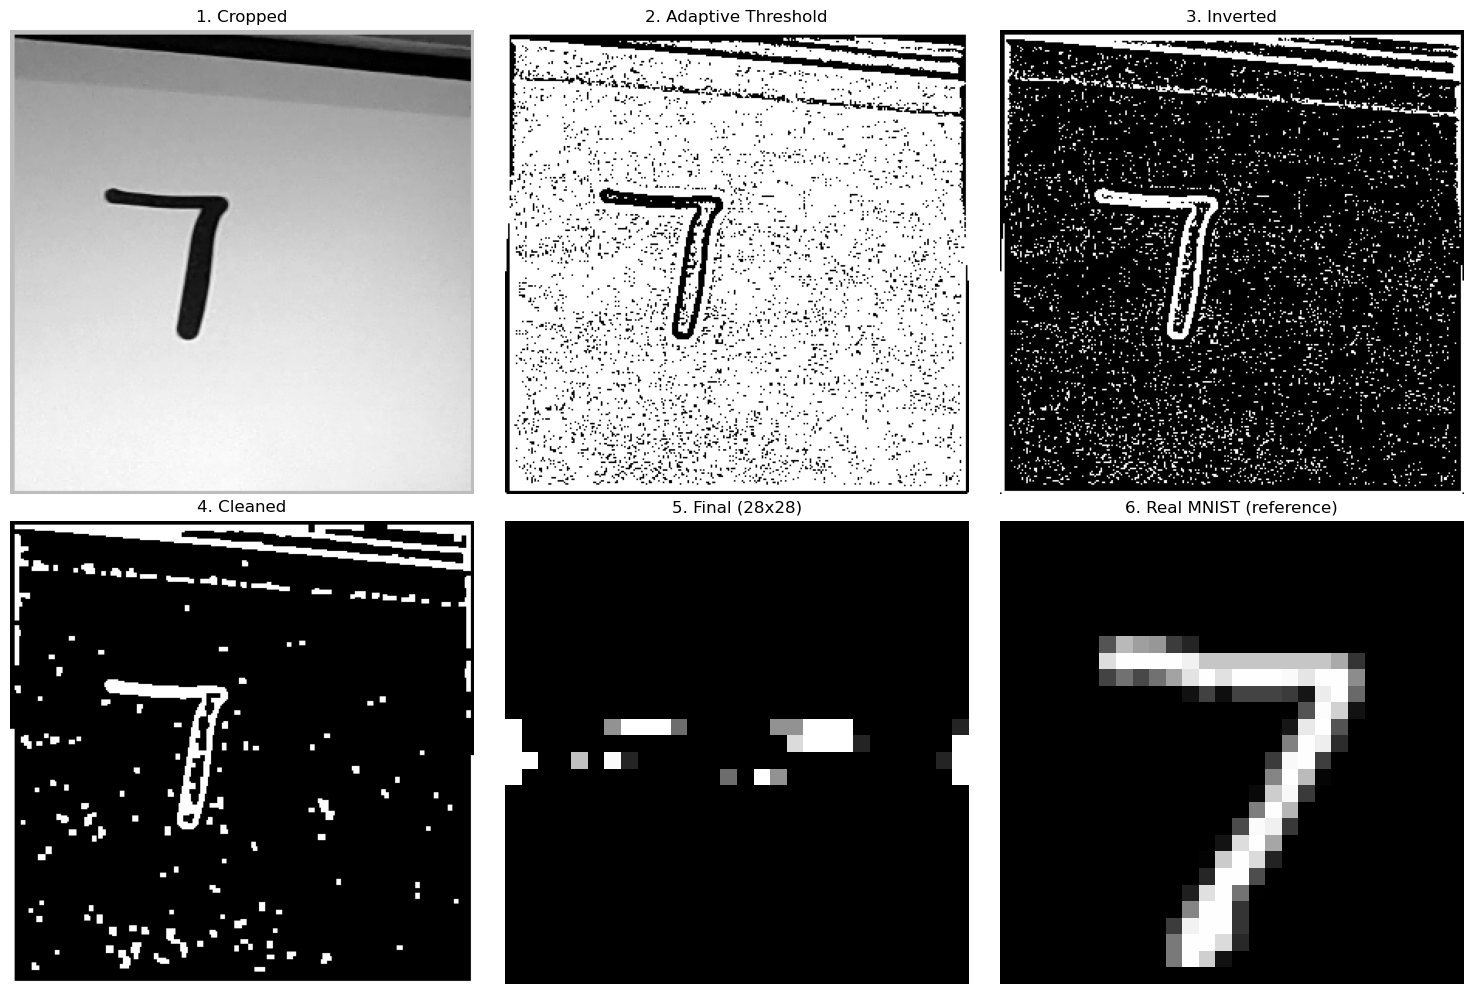


Final image stats:
Min: 0, Max: 255
Mean: 7.90
Non-zero pixels: 31/784

🎯 PREDICTION: 4
📊 Confidence: 0.496

📈 All confidence scores:
  0: 0.0079 
  1: 0.0192 
  2: 0.0133 
  3: 0.0213 
  4: 0.4960 █████████
  5: 0.0221 
  6: 0.0412 
  7: 0.0976 █
  8: 0.0398 
  9: 0.2415 ████

🏆 Top 3 predictions:
  1. Digit 4: 0.4960
  2. Digit 9: 0.2415
  3. Digit 7: 0.0976
Capturing and processing...


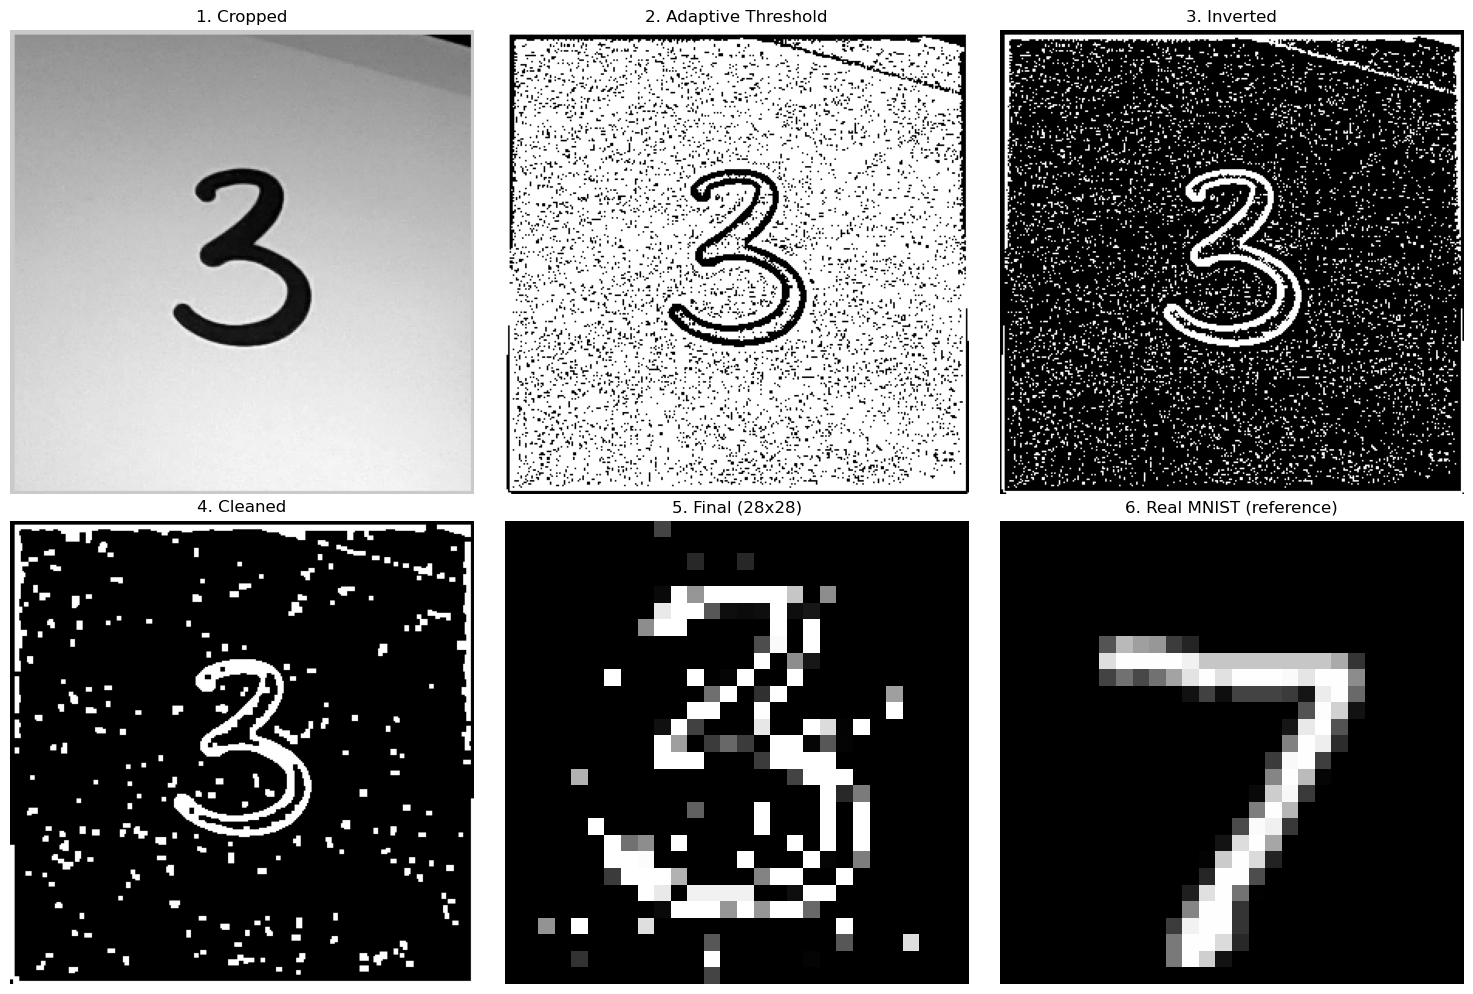


Final image stats:
Min: 0, Max: 255
Mean: 33.77
Non-zero pixels: 143/784

🎯 PREDICTION: 3
📊 Confidence: 0.941

📈 All confidence scores:
  0: 0.0022 
  1: 0.0003 
  2: 0.0048 
  3: 0.9409 ██████████████████
  4: 0.0000 
  5: 0.0489 
  6: 0.0001 
  7: 0.0005 
  8: 0.0021 
  9: 0.0001 

🏆 Top 3 predictions:
  1. Digit 3: 0.9409
  2. Digit 5: 0.0489
  3. Digit 2: 0.0048
Capturing and processing...


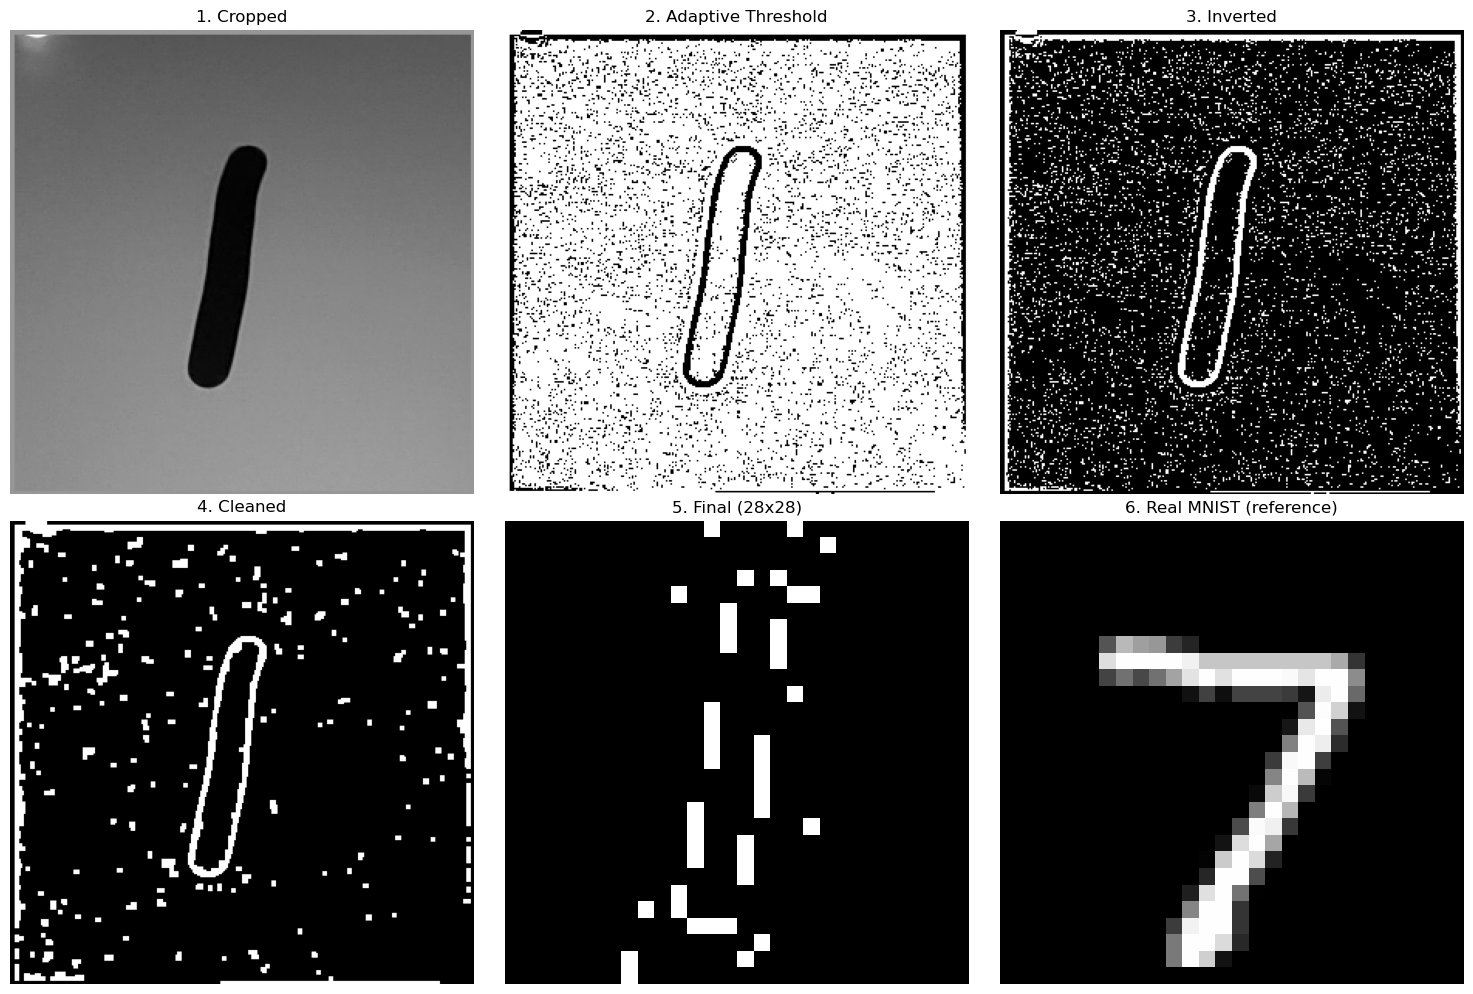


Final image stats:
Min: 0, Max: 255
Mean: 13.66
Non-zero pixels: 42/784

🎯 PREDICTION: 6
📊 Confidence: 0.211

📈 All confidence scores:
  0: 0.0356 
  1: 0.0588 █
  2: 0.1298 ██
  3: 0.1850 ███
  4: 0.0133 
  5: 0.0873 █
  6: 0.2105 ████
  7: 0.0865 █
  8: 0.1142 ██
  9: 0.0790 █

🏆 Top 3 predictions:
  1. Digit 6: 0.2105
  2. Digit 3: 0.1850
  3. Digit 2: 0.1298
Capturing and processing...


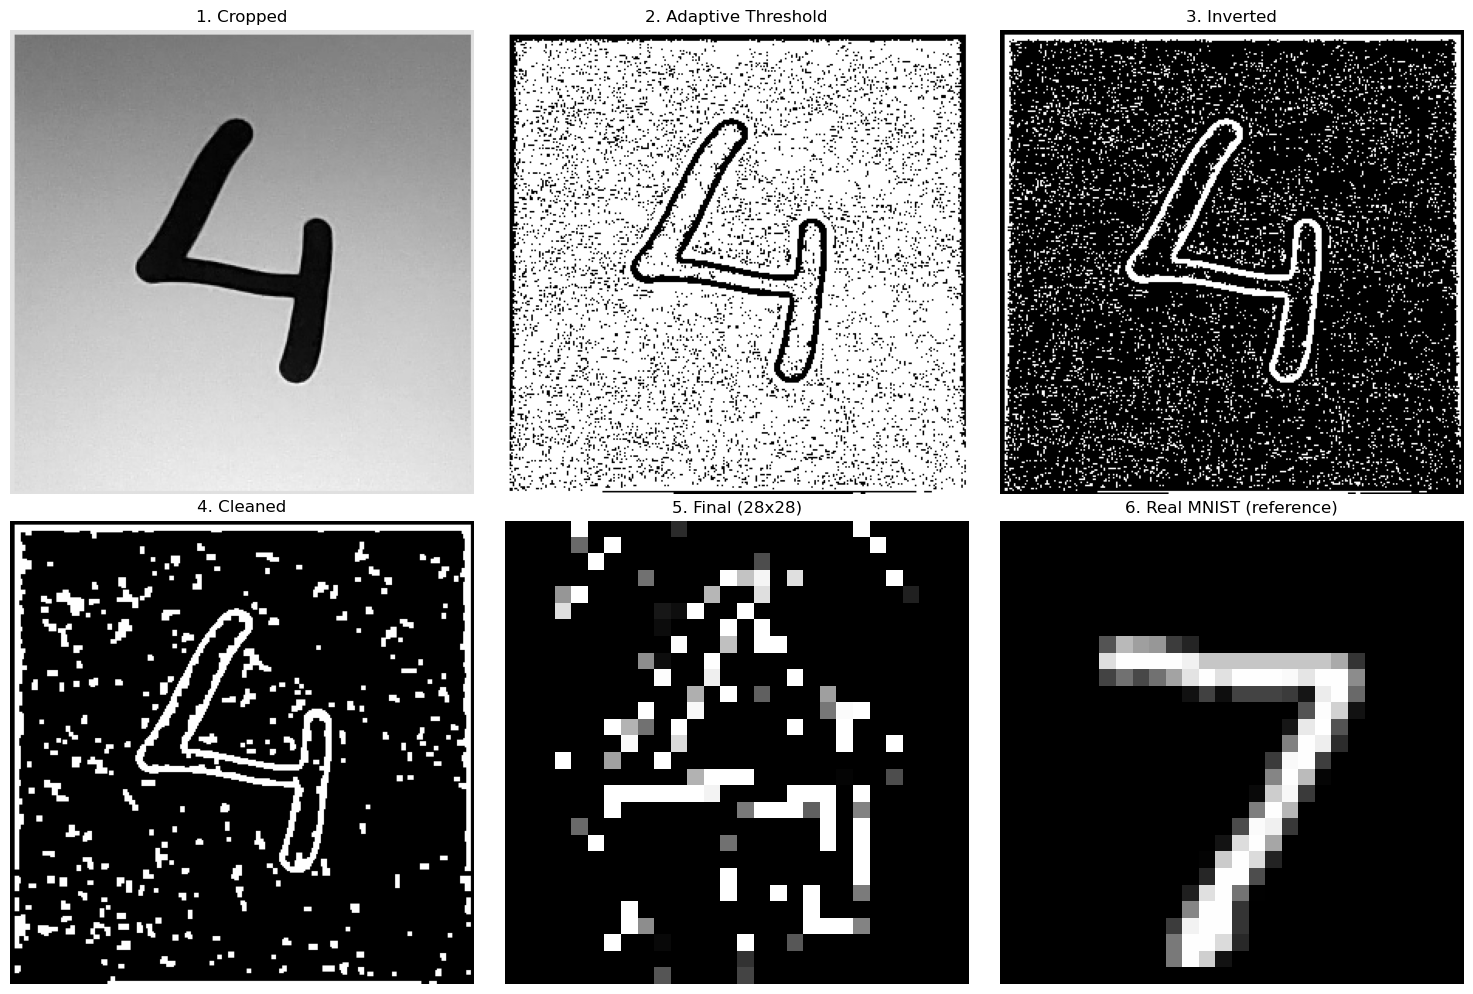


Final image stats:
Min: 0, Max: 255
Mean: 29.34
Non-zero pixels: 113/784

🎯 PREDICTION: 9
📊 Confidence: 0.569

📈 All confidence scores:
  0: 0.0551 █
  1: 0.0012 
  2: 0.0851 █
  3: 0.0704 █
  4: 0.0309 
  5: 0.0220 
  6: 0.0829 █
  7: 0.0658 █
  8: 0.0172 
  9: 0.5694 ███████████

🏆 Top 3 predictions:
  1. Digit 9: 0.5694
  2. Digit 2: 0.0851
  3. Digit 6: 0.0829


KeyboardInterrupt: 

In [ ]:
#Code from external source
import cv2
import torch
import matplotlib.pyplot as plt
import numpy as np

def better_webcam_classify():
    """
    Improved webcam classification with better preprocessing
    """
    print("=== IMPROVED WEBCAM DIGIT CLASSIFICATION ===")
    print("IMPORTANT INSTRUCTIONS:")
    print("1. Write a LARGE, THICK digit on WHITE paper with BLACK marker")
    print("2. Hold paper close to camera (fill most of the green box)")
    print("3. Make sure good lighting and high contrast")
    print("4. Press 'c' to capture, 'q' to quit")
    
    cap = cv2.VideoCapture(0)
    
    if not cap.isOpened():
        print("Error: Could not open webcam.")
        return
    
    while True:
        ret, frame = cap.read()
        
        if not ret:
            break
        
        # Draw larger crop area
        cv2.rectangle(frame, (50, 50), (350, 350), (0, 255, 0), 3)
        cv2.putText(frame, "Place LARGE digit here", (60, 40), 
                   cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)
        cv2.putText(frame, "Fill the box!", (60, 380), 
                   cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)
        
        cv2.imshow('Webcam - Write BIG digit in green box', frame)
        
        key = cv2.waitKey(1) & 0xFF
        
        if key == ord('c'):
            print("Capturing and processing...")
            
            # Step 1: Crop larger area
            captured = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
            cropped = captured[50:350, 50:350]  # Larger crop area
            
            # Step 2: Apply strong threshold to get pure black/white
            # Use adaptive threshold for better results
            thresh = cv2.adaptiveThreshold(cropped, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, 
                                         cv2.THRESH_BINARY, 11, 2)
            
            # Step 3: Invert so digit is white on black (like MNIST)
            inverted = 255 - thresh
            
            # Step 4: Clean up noise
            kernel = np.ones((3,3), np.uint8)
            cleaned = cv2.morphologyEx(inverted, cv2.MORPH_CLOSE, kernel)
            cleaned = cv2.morphologyEx(cleaned, cv2.MORPH_OPEN, kernel)
            
            # Step 5: Find contours to center the digit
            contours, _ = cv2.findContours(cleaned, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            
            if contours:
                # Find largest contour (should be the digit)
                largest_contour = max(contours, key=cv2.contourArea)
                x, y, w, h = cv2.boundingRect(largest_contour)
                
                # Extract digit region with some padding
                padding = 20
                x1 = max(0, x - padding)
                y1 = max(0, y - padding)
                x2 = min(cleaned.shape[1], x + w + padding)
                y2 = min(cleaned.shape[0], y + h + padding)
                
                digit_region = cleaned[y1:y2, x1:x2]
                
                # Resize to square
                size = max(digit_region.shape)
                square = np.zeros((size, size), dtype=np.uint8)
                y_offset = (size - digit_region.shape[0]) // 2
                x_offset = (size - digit_region.shape[1]) // 2
                square[y_offset:y_offset + digit_region.shape[0], 
                       x_offset:x_offset + digit_region.shape[1]] = digit_region
                
                # Resize to 28x28
                final_image = cv2.resize(square, (28, 28))
            else:
                print("No digit detected! Try writing larger and darker.")
                final_image = cv2.resize(cleaned, (28, 28))
            
            # Show processing steps
            fig, axes = plt.subplots(2, 3, figsize=(15, 10))
            
            axes[0, 0].imshow(cropped, cmap='gray')
            axes[0, 0].set_title('1. Cropped')
            axes[0, 0].axis('off')
            
            axes[0, 1].imshow(thresh, cmap='gray')
            axes[0, 1].set_title('2. Adaptive Threshold')
            axes[0, 1].axis('off')
            
            axes[0, 2].imshow(inverted, cmap='gray')
            axes[0, 2].set_title('3. Inverted')
            axes[0, 2].axis('off')
            
            axes[1, 0].imshow(cleaned, cmap='gray')
            axes[1, 0].set_title('4. Cleaned')
            axes[1, 0].axis('off')
            
            axes[1, 1].imshow(final_image, cmap='gray')
            axes[1, 1].set_title('5. Final (28x28)')
            axes[1, 1].axis('off')
            
            # Compare with real MNIST
            from torchvision import datasets, transforms
            test_data = datasets.MNIST('MNIST', train=False, download=True, transform=transforms.ToTensor())
            mnist_sample = test_data[0][0].squeeze().numpy()
            axes[1, 2].imshow(mnist_sample, cmap='gray')
            axes[1, 2].set_title('6. Real MNIST (reference)')
            axes[1, 2].axis('off')
            
            plt.tight_layout()
            plt.show()
            
            # Print image statistics
            print(f"\nFinal image stats:")
            print(f"Min: {final_image.min()}, Max: {final_image.max()}")
            print(f"Mean: {final_image.mean():.2f}")
            print(f"Non-zero pixels: {np.count_nonzero(final_image)}/{28*28}")
            
            # Classify
            image_tensor = torch.tensor(final_image, dtype=torch.float32).to(device)
            image_tensor = image_tensor / 255.0
            image_tensor = image_tensor.view(1, 28*28)  # Add batch dimension
            
            model.eval()
            with torch.no_grad():
                output = model(image_tensor)
                probabilities = torch.softmax(output, dim=1).squeeze()
                prediction = output.argmax(dim=1).item()
                confidence = probabilities.max().item()
            
            print(f"\n🎯 PREDICTION: {prediction}")
            print(f"📊 Confidence: {confidence:.3f}")
            
            # Show all confidence scores
            print(f"\n📈 All confidence scores:")
            for i in range(10):
                bar = "█" * int(probabilities[i] * 20)
                print(f"  {i}: {probabilities[i]:.4f} {bar}")
            
            # Show top 3
            top3_indices = probabilities.topk(3).indices
            top3_probs = probabilities.topk(3).values
            print(f"\n🏆 Top 3 predictions:")
            for i in range(3):
                print(f"  {i+1}. Digit {top3_indices[i].item()}: {top3_probs[i].item():.4f}")
            
        elif key == ord('q'):
            break
    
    cap.release()
    cv2.destroyAllWindows()

# Alternative: Manual threshold adjustment
def manual_threshold_classify():
    """
    Classification with manual threshold control
    """
    print("=== MANUAL THRESHOLD WEBCAM CLASSIFICATION ===")
    
    cap = cv2.VideoCapture(0)
    threshold_val = 127
    
    if not cap.isOpened():
        print("Error: Could not open webcam.")
        return
    
    print("Controls:")
    print("- 'c': capture and classify")
    print("- '+': increase threshold")
    print("- '-': decrease threshold") 
    print("- 'q': quit")
    
    while True:
        ret, frame = cap.read()
        if not ret:
            break
        
        # Show live preprocessing
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        cropped = gray[50:350, 50:350]
        _, thresh = cv2.threshold(cropped, threshold_val, 255, cv2.THRESH_BINARY)
        inverted = 255 - thresh
        
        # Show both original and processed
        combined = np.hstack((frame[50:350, 50:350], cv2.cvtColor(inverted, cv2.COLOR_GRAY2BGR)))
        
        cv2.putText(combined, f"Threshold: {threshold_val}", (10, 30), 
                   cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 0), 2)
        cv2.imshow('Original vs Processed', combined)
        
        key = cv2.waitKey(1) & 0xFF
        
        if key == ord('c'):
            final_image = cv2.resize(inverted, (28, 28))
            
            plt.figure(figsize=(6, 3))
            plt.subplot(1, 2, 1)
            plt.imshow(inverted, cmap='gray')
            plt.title('Processed')
            plt.axis('off')
            
            plt.subplot(1, 2, 2)
            plt.imshow(final_image, cmap='gray')
            plt.title('Final (28x28)')
            plt.axis('off')
            plt.show()
            
            # Classify
            image_tensor = torch.tensor(final_image, dtype=torch.float32).to(device)
            image_tensor = image_tensor / 255.0
            image_tensor = image_tensor.view(1, 28*28)
            
            model.eval()
            with torch.no_grad():
                output = model(image_tensor)
                prediction = output.argmax(dim=1).item()
                probabilities = torch.softmax(output, dim=1).squeeze()
            
            print(f"Prediction: {prediction}")
            print("Top 3:", [(i.item(), p.item()) for i, p in zip(probabilities.topk(3).indices, probabilities.topk(3).values)])
            
        elif key == ord('=') or key == ord('+'):
            threshold_val = min(255, threshold_val + 5)
        elif key == ord('-'):
            threshold_val = max(0, threshold_val - 5)
        elif key == ord('q'):
            break
    
    cap.release()
    cv2.destroyAllWindows()

# Run the improved classification
print("Starting improved webcam classification...")
better_webcam_classify()

# 4. Post-practical questionnaire

Please complete the week 2 post-practical questionnaire on iLearn.